In [ ]:
from matplotlib import pyplot as plt
from PIL import Image
import numpy as np
# import the modules
import os
from os import listdir

In [15]:
class ConvLayer:

    def __init__(self, num_filters=1, filter_size=3):

        self.num_filters = num_filters
        self.filter_size = filter_size

        self.filters = (
            np.random.randn(
                num_filters,
                filter_size,
                filter_size
            ) * 0.1
        )

    def forward(self, image):

        self.image = image

        h, w = image.shape
        fs = self.filter_size

        output = np.zeros(
            (
                self.num_filters,
                h-fs+1,
                w-fs+1
            )
        )

        for f in range(self.num_filters):

            for i in range(h-fs+1):
                for j in range(w-fs+1):

                    region = image[i:i+fs, j:j+fs]

                    output[f, i, j] = np.sum(
                        region * self.filters[f]
                    )

        return output

    def backward(self, d_out, learning_rate):

        fs = self.filter_size

        d_filters = np.zeros_like(self.filters)

        h, w = self.image.shape

        for f in range(self.num_filters):

            for i in range(h-fs+1):
                for j in range(w-fs+1):

                    region = self.image[
                        i:i+fs,
                        j:j+fs
                    ]

                    d_filters[f] += (
                        d_out[f, i, j] * region
                    )

        self.filters -= learning_rate * d_filters

In [16]:
class Flatten:

    def forward(self, x):
        self.shape = x.shape
        return x.reshape(1, -1)

    def backward(self, grad):
        return grad.reshape(self.shape)

In [17]:
class ReLU:

    def forward(self, x):

        self.input = x

        return np.maximum(0, x)

    def backward(self, grad):

        return grad * (self.input > 0)

In [18]:
class MaxPool:

    def forward(self, x):

        self.input = x

        channels, h, w = x.shape

        output = np.zeros(
            (
                channels,
                h//2,
                w//2
            )
        )

        for c in range(channels):

            for i in range(0, h, 2):
                for j in range(0, w, 2):

                    region = x[c, i:i+2, j:j+2]

                    output[c, i//2, j//2] = np.max(region)

        return output
    
    def backward(self, grad):

        channels, h, w = self.input.shape

        d_input = np.zeros_like(self.input)

        for c in range(channels):
            for i in range(0, h-1, 2):
                for j in range(0, w-1, 2):

                    region = self.input[c, i:i+2, j:j+2]

                    max_pos = np.unravel_index(
                        np.argmax(region),
                        region.shape
                    )

                    d_input[
                        c,
                        i + max_pos[0],
                        j + max_pos[1]
                    ] = grad[c, i//2, j//2]

        return d_input

In [19]:
class Dense:

    def __init__(self, input_size, output_size):

        self.weights = (
            np.random.randn(input_size, output_size)
            * np.sqrt(2/input_size)
        )

        self.biases = np.zeros((1, output_size))

    def forward(self, x):

        self.input = x

        return np.dot(x, self.weights) + self.biases

    def backward(self, grad, lr):

        dw = np.dot(self.input.T, grad)

        db = np.sum(grad, axis=0, keepdims=True)

        dx = np.dot(grad, self.weights.T)

        self.weights -= lr * dw
        self.biases -= lr * db

        return dx

In [20]:
class Sigmoid:

    def forward(self, x):

        self.output = 1/(1+np.exp(-x))

        return self.output

    def backward(self, grad):

        return (
            grad *
            self.output *
            (1-self.output)
        )

In [21]:
conv = ConvLayer(num_filters=1)

relu = ReLU()

pool = MaxPool()

flat = Flatten()

dense = Dense(
    input_size=31*31,
    output_size=1
)

sigmoid = Sigmoid()

def forward(image):

    x = conv.forward(image)

    x = relu.forward(x)

    x = pool.forward(x)

    x = flat.forward(x)

    x = dense.forward(x)

    x = sigmoid.forward(x)

    return x

"""
def backward(image):
    x = sigmoid.backward(image)
    x = dense.backward(x)
    x = flat.backward(x)
    x = pool.backward(x)
    x = relu.backward(x)
    x = conv.backward (x)






    return x

"""



NameError: name 'np' is not defined

In [ ]:
def loss(y_true, y_pred):

    eps = 1e-7

    return -(
        y_true*np.log(y_pred+eps)
        +
        (1-y_true)*np.log(
            1-y_pred+eps
        )
    )

In [ ]:
"""
from matplotlib import pyplot as plt
from PIL import Image
import numpy as np
# import the modules
import os
from os import listdir

learning_rate = 0.001
print("Not Robin")
y_true = np.array([[0]])
folder_dir = "dataset/NotRobin"


for images in os.listdir(folder_dir):
    if (images.endswith(".jpg")):
        img = Image.open(folder_dir+"/"+images)

        img = img.convert("L")

        img = img.resize((64,64))

        image = np.array(img)/255.0
        for epoch in range(1000):

            prediction = forward(image)
            grad = prediction - y_true

            grad = dense.backward(grad, learning_rate)

        print("Prediction:", prediction)

        print(
            "Loss:",
            loss(y_true, prediction)
        )
        predicted_class = 1 if prediction[0][0] > 0.5 else 0

print(
    "Robin" if predicted_class == 1
    else "NotRobin"
)

y_true = np.array([[1]])


print("Robin")
folder_dir = "dataset/Robin"
for images in os.listdir(folder_dir):
    if (images.endswith(".jpg")):
        img = Image.open(folder_dir+"/"+images)

        img = img.convert("L")

        img = img.resize((64,64))

        image = np.array(img)/255.0
        for epoch in range(1000):
            prediction = forward(image)

            grad = prediction - y_true

            grad = dense.backward(grad, learning_rate)


        print("Prediction:", prediction)

        print(
            "Loss:",
            loss(y_true, prediction)
        )
        predicted_class = 1 if prediction[0][0] > 0.5 else 0

print(
    "Robin" if predicted_class == 1
    else "NotRobin"
)
"""

'\nfrom matplotlib import pyplot as plt\nfrom PIL import Image\nimport numpy as np\n# import the modules\nimport os\nfrom os import listdir\n\nlearning_rate = 0.001\nprint("Not Robin")\ny_true = np.array([[0]])\nfolder_dir = "dataset/NotRobin"\n\n\nfor images in os.listdir(folder_dir):\n    if (images.endswith(".jpg")):\n        img = Image.open(folder_dir+"/"+images)\n\n        img = img.convert("L")\n\n        img = img.resize((64,64))\n\n        image = np.array(img)/255.0\n        for epoch in range(1000):\n\n            prediction = forward(image)\n            grad = prediction - y_true\n\n            grad = dense.backward(grad, learning_rate)\n\n        print("Prediction:", prediction)\n\n        print(\n            "Loss:",\n            loss(y_true, prediction)\n        )\n        predicted_class = 1 if prediction[0][0] > 0.5 else 0\n\nprint(\n    "Robin" if predicted_class == 1\n    else "NotRobin"\n)\n\ny_true = np.array([[1]])\n\n\nprint("Robin")\nfolder_dir = "dataset/Robin"

Before -0.0010152403615638049
Conv [[ 0.02503635 -0.01614333 -0.117922  ]
 [ 0.1280543  -0.02653468  0.00167707]
 [-0.01517133 -0.02543074 -0.07461928]]
Epoch   0 Loss=12.4682 Accuracy=61.11%
Epoch   1 Loss=12.4677 Accuracy=50.00%
Epoch   2 Loss=12.4671 Accuracy=44.44%
Epoch   3 Loss=12.4661 Accuracy=44.44%
Epoch   4 Loss=12.4644 Accuracy=55.56%
Epoch   5 Loss=12.4627 Accuracy=44.44%
Epoch   6 Loss=12.4618 Accuracy=55.56%
Epoch   7 Loss=12.4597 Accuracy=61.11%
Epoch   8 Loss=12.4580 Accuracy=55.56%
Epoch   9 Loss=12.4568 Accuracy=55.56%
Epoch  10 Loss=12.4562 Accuracy=61.11%
Epoch  11 Loss=12.4552 Accuracy=55.56%
Epoch  12 Loss=12.4537 Accuracy=55.56%
Epoch  13 Loss=12.4527 Accuracy=55.56%
Epoch  14 Loss=12.4513 Accuracy=55.56%
Epoch  15 Loss=12.4513 Accuracy=55.56%
Epoch  16 Loss=12.4508 Accuracy=55.56%
Epoch  17 Loss=12.4491 Accuracy=55.56%
Epoch  18 Loss=12.4482 Accuracy=55.56%
Epoch  19 Loss=12.4476 Accuracy=50.00%
Epoch  20 Loss=12.4463 Accuracy=50.00%
Epoch  21 Loss=12.4455 Accur

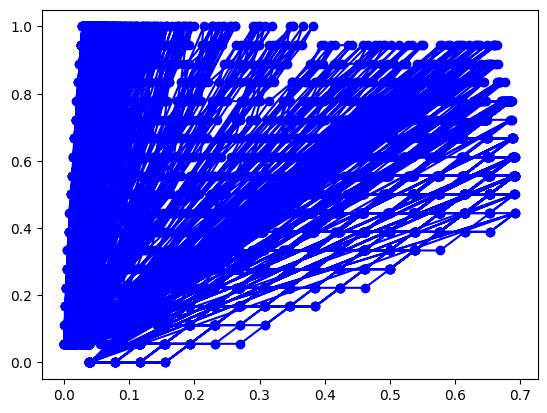

In [ ]:

from matplotlib import pyplot as plt
from PIL import Image
import numpy as np
# import the modules
import os
from os import listdir

learning_rate = 0.01

folder_dir = "dataset/NotRobin"

training_data = []
for images in os.listdir(folder_dir):
    if (images.endswith(".jpg")):
        img = Image.open(folder_dir+"/"+images)

        img = img.convert("L")

        img = img.resize((64,64))

        image = np.array(img)/255.0
        training_data.append((image, 0))

folder_dir = "dataset/Robin"

for images in os.listdir(folder_dir):
    if (images.endswith(".jpg")):
        img = Image.open(folder_dir+"/"+images)

        img = img.convert("L")

        img = img.resize((64,64))

        image = np.array(img)/255.0
        training_data.append((image, 1))


print("Before",
      np.mean(dense.weights))
print("Conv",conv.filters[0])
loss_history=[]
accuracy_history=[]



for epoch in range(250):
    total_loss = 0
    correct = 0

    np.random.shuffle(training_data)

    for image, label in training_data:

        y_true = np.array([[label]])

        prediction = forward(image)

        total_loss += loss(y_true, prediction)[0][0]

        predicted_class = int(prediction[0][0] > 0.5)

        if predicted_class == label:
            correct += 1

        grad = prediction - y_true

        grad = sigmoid.backward(grad)

        grad = dense.backward(grad, learning_rate)


        grad = flat.backward(grad)

        grad = pool.backward(grad)

        grad = relu.backward(grad)

        grad = conv.backward(grad, learning_rate)
        accuracy=correct/len(training_data)
        avg_loss=avg_loss = total_loss / len(training_data)
        loss_history.append(avg_loss)
        accuracy_history.append(accuracy)


        
    print(
    f"Epoch {epoch:3d} "
    f"Loss={total_loss:.4f} "
    f"Accuracy={correct/len(training_data):.2%}"
    )
print("Conv",conv.filters[0])
print("After",
      np.mean(dense.weights))
plt.plot(loss_history, accuracy_history, color="blue", marker="o", linestyle="-", label="Trend Line")


In [ ]:
print("\nTesting")
folder_dir = "dataset/test/NotRobin"

training_data = []
for images in os.listdir(folder_dir):
    if (images.endswith(".jpg")):
        img = Image.open(folder_dir+"/"+images)

        img = img.convert("L")

        img = img.resize((64,64))

        image = np.array(img)/255.0
        training_data.append((image, 0))

folder_dir = "dataset/test/Robin"

for images in os.listdir(folder_dir):
    if (images.endswith(".jpg")):
        img = Image.open(folder_dir+"/"+images)

        img = img.convert("L")

        img = img.resize((64,64))

        image = np.array(img)/255.0
        training_data.append((image, 1))


for image, label in training_data:

    prediction = forward(image)

    predicted_class = int(prediction[0][0] > 0.5)

    print(
        prediction[0][0],
        predicted_class,
        label
    )


Testing
0.38771293096772935 0 0
0.10136496051839901 0 0
0.7102942120228962 1 0
0.810022415572368 1 0
0.13530618276202422 0 0
0.011010238863960532 0 1
0.7940745156481472 1 1
0.9714536281661624 1 1
0.9984611164147564 1 1
0.011815087993048966 0 1


In [ ]:
TP = TN = FP = FN = 0
folder_dir = "dataset/test/NotRobin"

training_data = []
for images in os.listdir(folder_dir):
    if (images.endswith(".jpg")):
        img = Image.open(folder_dir+"/"+images)

        img = img.convert("L")

        img = img.resize((64,64))

        image = np.array(img)/255.0
        training_data.append((image, 0))

folder_dir = "dataset/test/Robin"

for images in os.listdir(folder_dir):
    if (images.endswith(".jpg")):
        img = Image.open(folder_dir+"/"+images)

        img = img.convert("L")

        img = img.resize((64,64))

        image = np.array(img)/255.0
        training_data.append((image, 1))


for image, label in training_data:

    prediction = forward(image)

    pred = int(prediction[0][0] > 0.5)

    if pred == 1 and label == 1:
        TP += 1
    elif pred == 0 and label == 0:
        TN += 1
    elif pred == 1 and label == 0:
        FP += 1
    else:
        FN += 1

print("TP =", TP)
print("TN =", TN)
print("FP =", FP)
print("FN =", FN)

TP = 3
TN = 4
FP = 1
FN = 2


In [ ]:
w_before = dense.weights.copy()

prediction = forward(image)

grad = prediction - y_true
dense.backward(grad, 0.001)

print(np.sum(np.abs(dense.weights - w_before)))

0.7741439394027424
